# Gráficas con Seaborn

In [16]:
import pandas as pd
import seaborn as sns

La librería `seaborn` es otra librería muy común para la representación de gráficos. Está construida sobre Matplotlib y proporciona una interfaz de alto nivel para crear visualizaciones estadísticas atractivas y profesionales. Una de sus principales ventajas es que incluye temas visuales predefinidos y paletas de colores que mejoran significativamente el aspecto de los gráficos por defecto.

Permite realizar operaciones similares a las de `pandas` o `matplotlib`, pero destaca especialmente en la creación de gráficos estadísticos complejos como diagramas de violín, gráficos de distribución, mapas de calor y gráficos de regresión, todo ello con pocas líneas de código.

La documentación completa está en: https://seaborn.pydata.org/index.html

In [ ]:
#Se emplea el código de esta celda solo si se está ejecutando el código en Google Collaboratory (se emplea para obtener los datos)
#En caso de estar ejecutando el código en un equipo local, no es necesario volver a descargar los datos

#  ! git clone https://github.com/bbaruque/VisDat_Ejemplos.git
#  data_dir = "./VisDat_Ejemplos/JupyterNotebooks/data/datos_1ªy2ªParte/"  

In [18]:
# En caso de haber ejecutado la celda anterior, esta debe dejarse SIN EJECUTAR
data_dir = "../../data/datos_1ªy2ªParte/"

In [19]:
reviews = pd.read_csv(data_dir+"winemag-data_first150k.csv", index_col=0)
reviews.head(3)

,country,description,designation,points,price,province,region_1,region_2,variety,winery
0,US,This tremendous 100% varietal wine hails from ...,Martha's Vineyard,96,235.0,California,Napa Valley,Napa,Cabernet Sauvignon,Heitz
1,Spain,"Ripe aromas of fig, blackberry and cassis are ...",Carodorum Selección Especial Reserva,96,110.0,Northern Spain,Toro,NaN,Tinta de Toro,Bodega Carmen Rodríguez
2,US,Mac Watson honors the memory of a wine once ma...,Special Selected Late Harvest,96,90.0,California,Knights Valley,Sonoma,Sauvignon Blanc,Macauley


## Countplot

Equivalente al gráfico de barras ya visto en pandas

<Axes: xlabel='points', ylabel='count'>

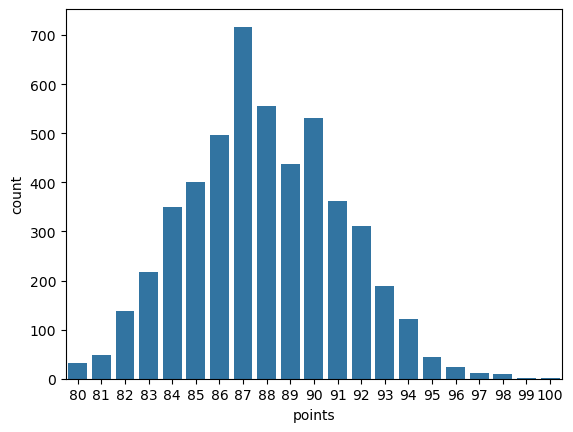

In [21]:
# Seleccionamos solo una muestra de los datos para agilizar el proceso.
sns.countplot(x='points', data=reviews.sample(5000))

La mayor diferencia con `pandas` es que en este caso no es necesario realizar las cuentas de forma explícita (con `value_counts`); la propia función se encarga de agregar los datos de la columna seleccionada.

Seaborn no tiene equivalentes exactos a los gráficos de línea o de área; en su lugar se puede usar la función `kdeplot`.

## KDEplot

<Axes: xlabel='price', ylabel='Density'>

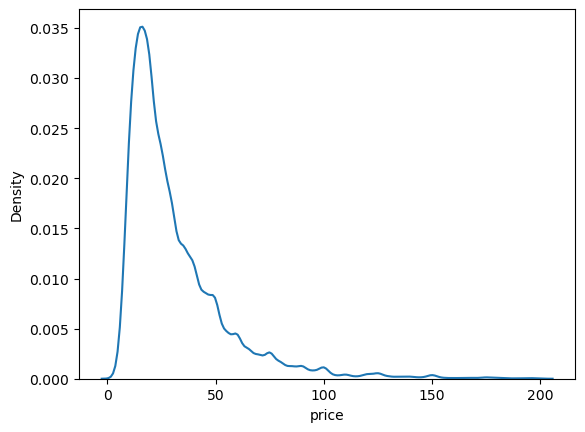

In [ ]:
sns.kdeplot(reviews.query('price < 200').price)

KDE son las siglas de "Kernel Density Estimator". Es una técnica estadística que permite suavizar los picos que aparecen en las gráficas cuando hay valores medidos incorrectamente o que pueden variar sin que resulte apreciable para el problema (pero sí para la visualización).

Por ejemplo, varios vinos cuyo precio sea 20 € y uno solo sea de 19.93 € deberían considerarse aproximadamente iguales.

Veamos la diferencia con un gráfico de línea como los ya conocidos:

<Axes: xlabel='price'>

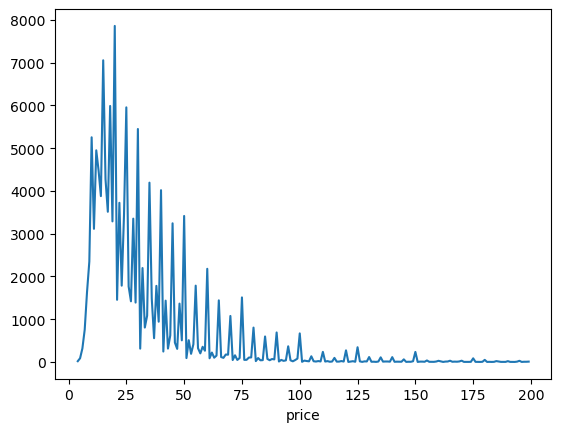

In [ ]:
reviews[reviews['price'] < 200]['price'].value_counts().sort_index().plot.line()

Como vemos, la gráfica de KDE es mejor que la de línea simple para visualizar la "verdadera" forma de los datos en un intervalo. Se recomienda en estas situaciones.

Sin embargo, resulta una elección peor cuando se trata de datos categóricos ordinales: el KDE espera que, si hay 200 vinos con puntuaciones de 85 y 400 con 86, los valores intermedios, p. ej. 85,5, deberían suavizarse hacia valores intermedios. Si ese valor no existe (no hay notas con decimales), se está intentando ajustar a valores que no se contemplan en el problema.

En estos casos, un diagrama de línea es lo más adecuado.

Se pueden emplear gráficos KDE en 2 dimensiones:

<Axes: xlabel='price', ylabel='points'>

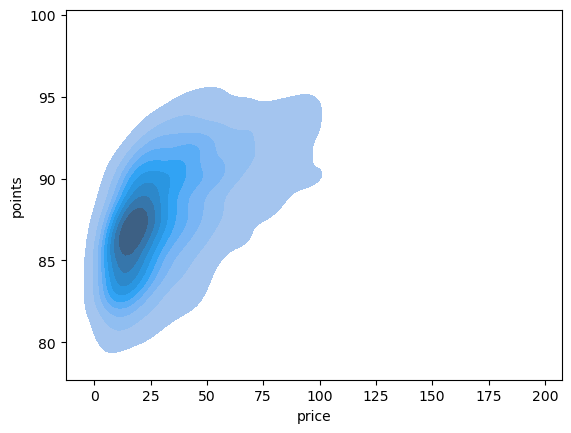

In [ ]:
# De la tabla 'reviews' se obtienen aquellas entradas con precio menor a 200
# Se extraen las columnas 'price', 'points' (para todas las entradas que quedaban)
# Se eliminan aquellas entradas que contengan valores `nan` (datos faltantes) con dropna
# Se seleccionan aleatoriamente 5000
price_less_200 = reviews[reviews['price'] < 200].loc[:, ['price', 'points']].dropna().sample(5000)

# Usar la forma recomendada: pasar `data` y nombrar las columnas con x= e y=
# Esto evita el error "takes from 0 to 1 positional arguments but 2 were given"
# Opción recomendada (2D KDE):
sns.kdeplot(data=price_less_200, x='price', y='points', fill=True)

# Alternativa equivalente usando arrays pero con nombres explícitos:
# sns.kdeplot(x=price_less_200['price'], y=price_less_200['points'], fill=True)

Es el gráfico equivalente al hexplot que se vio en el tema 2. Como vemos, es otra forma de resolver el problema de 'overplotting' (sobreposición de puntos) que vimos anteriormente (con el scatterplot o gráfico de dispersión). Es conveniente destacar que es muy computacionalmente intensivo y por eso se ha reducido la muestra de datos a 5000.

## Histplot y Displot

Se trata de las funciones equivalentes al histograma que se ha visto en `pandas`. Se recomienda usar la función `histplot` para histogramas simples o `displot` para una visualización más completa.

<Axes: xlabel='points', ylabel='Count'>

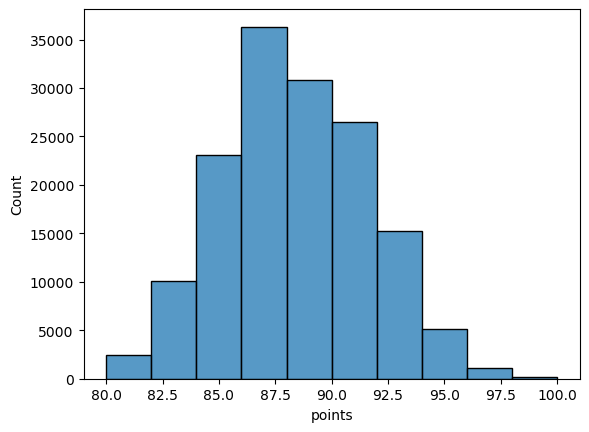

In [ ]:
# Usando histplot para un histograma simple
sns.histplot(data=reviews, x='points', bins=10)

Es un tipo de gráfica que se puede personalizar de varias formas. Por ejemplo, podemos añadir una estimación de densidad (KDE) sobre el histograma. En el ejemplo anterior se especifica, para mejor visualización, que solo se creen 10 intervalos: son suficientes para incluir 2 valores de la columna `points` por cada barra.

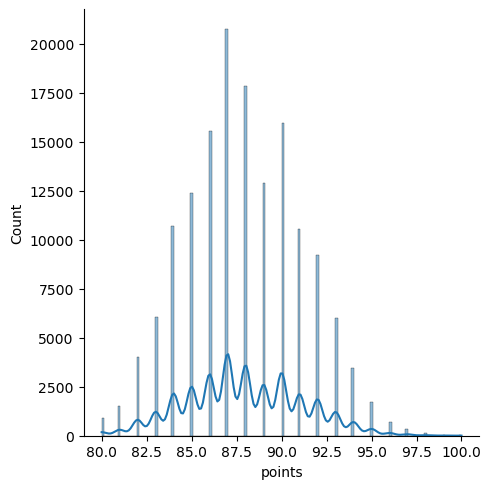

In [ ]:
# Usando displot para una visualización más completa con KDE
sns.displot(data=reviews, x='points', kde=True)

## Scatterplot y hexplot

Para representar dos variables, una en función de la otra, en Seaborn se emplea la función `jointplot`.

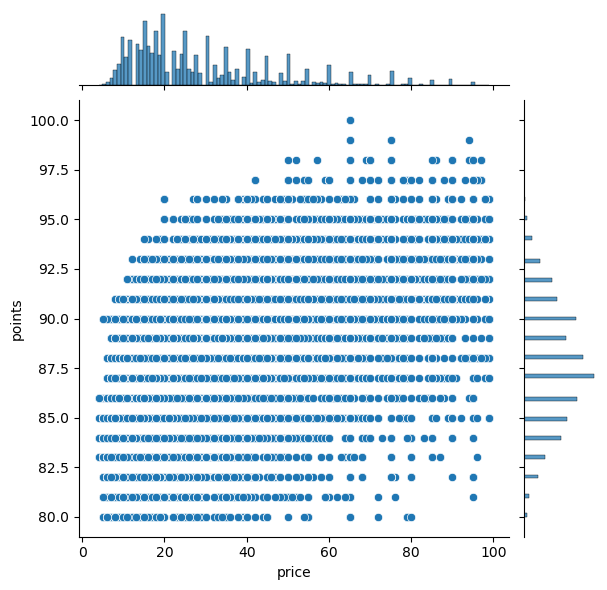

In [ ]:
sns.jointplot(x='price', y='points', data=reviews[reviews['price'] < 100])

Se añade el cálculo del coeficiente de Pearson y un histograma que permite ver cuántas muestras caen en cada fila o columna. Muchos gráficos de Seaborn incluyen este tipo de información extra.

Por lo demás, es igual al scatterplot de pandas.

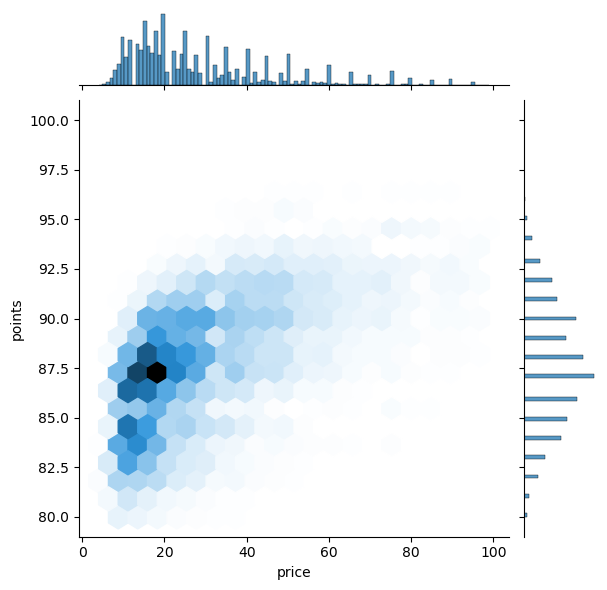

In [ ]:
sns.jointplot(x='price', y='points', data=reviews[reviews['price'] < 100], kind='hex', gridsize=20)

## Gráficas de Caja y de Violín (Boxplot y violin plot)

<Axes: xlabel='variety', ylabel='points'>

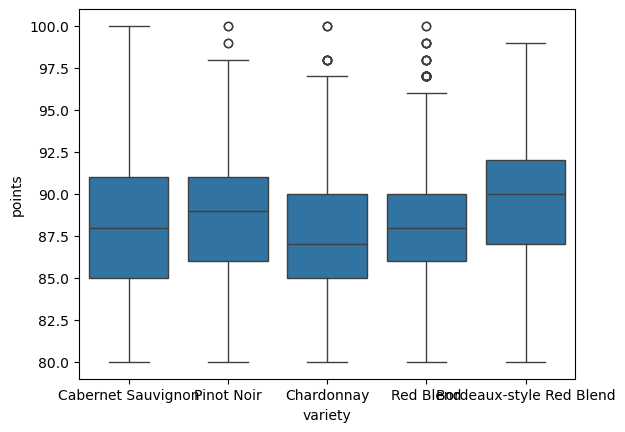

In [ ]:
df = reviews[reviews.variety.isin(reviews.variety.value_counts().head(5).index)]

sns.boxplot(
    x='variety',
    y='points',
    data=df
)

Por cada variable aparece una caja, en el centro de las distribuciones.

La parte superior de la misma representa el percentil 75 de la muestra, mientras que la parte inferior representa el percentil 25. Es decir, los rangos en los que se puede incluir la mitad de los datos aparecen representados en la caja. La línea dibujada en el medio es la mediana.

Las líneas o "bigotes" indican hasta donde se extienden las muestras de datos más allá del centro de la distribución. Los puntos individuales más allá de estos representan outliers (puntos individuales muy distanciados del resto).

Se puede comprobar que aunque las 5 variedades reciben aproximadamente las mismas puntuaciones, los vinos de "Bordeaux" (derecha) tienden a ser valorados un poco mejor que los "Chardonnay" (centro).

--- 

La ventaja de este tipo de gráficos es que se pueden emplear en muchos tipos de datos. Tampoco tienen límite de uso: se pueden incluir tantas cajas como haya espacio.

Como restricción: solo funcionan con variables de intervalo y variables nominales con un número grande de posibles valores. Además, asumen que los datos se distribuyen en una distribución normal y no aportan mucha información sobre los valores individuales.

<Axes: xlabel='variety', ylabel='points'>

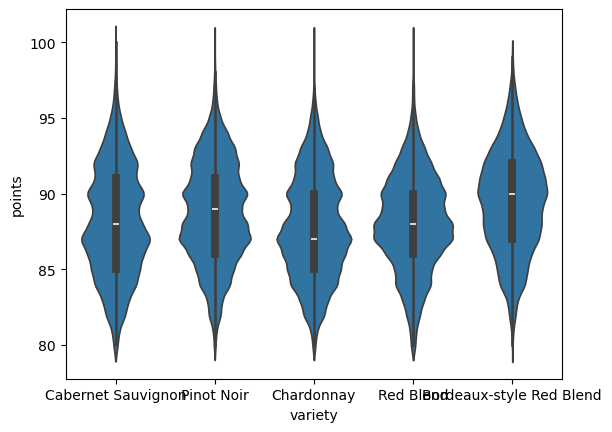

In [ ]:
sns.violinplot(
    x='variety',
    y='points',
    data=reviews[reviews.variety.isin(reviews.variety.value_counts()[:5].index)]
)

En este caso, la caja del boxplot se reemplaza por una estimación KDE de la distribución de los datos. La información representada es similar, pero puede ser más intuitiva de interpretar (a mayor anchura, mayor número de datos que incluyen ese valor).

## ¿Por qué emplear Seaborn?

En ambos tipos de gráficas, se añaden las muestras de datos individuales sobre la gráfica
como puntos. Si hay muchos datos, puede no ser conveniente (igual que en los gráficos de dispersión)
porque la información se puede solapar. Vamos a crear otro gráfico sin los puntos individuales: